# Sparse AFM-IR reconstruction with CACNP

This example reconstructs the multi-particle PS–PMMA/epoxy hyperspectral cube using the published pretrained model. No training spectral corpus or sample-specific retraining is required. Place this notebook in the repository root alongside the `code`, `data`, and `models` folders.

The inputs are spectra from randomly selected spatial positions and three full-field structure images at zero-based channel indices **[107, 72, 242]** (1189, 1049, and 1729 cm⁻¹). Context fractions are **0.1%, 0.5%, 1%, 5%, and 10%**. The context sets are nested: each larger set contains every point from the preceding set. Structure images are additional measurements, not part of these spatial context percentages.

For each context fraction, the notebook performs two predictions:
1. Condition on approximately 70% of the measured context and estimate an uncertainty scale using the held-out 30%.
2. Condition on all measured context and apply that scale to the predicted standard deviations.

The final figure shows nearest-neighbor filling with measured locations in red, the CACNP mean, and calibrated uncertainty at channel **97 (1149 cm⁻¹)**. The full measured cube is used here to simulate sparse measurements and evaluate predictions; this is a retrospective reconstruction example, not instrument control.


In [18]:
from pathlib import Path
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt

# Keep CPU inference responsive on machines with many logical cores.
if not torch.cuda.is_available():
    torch.set_num_threads(min(2, torch.get_num_threads()))

# Find this repository 
_cwd = Path.cwd().resolve()
REPO_ROOT = next(
    (p for p in (_cwd, *_cwd.parents) if (p / "code" / "conv_cnp_afmir_prob.py").is_file()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Could not find code/conv_cnp_afmir_prob.py. Open this notebook from inside the GitHub repository."
    )
sys.path.insert(0, str(REPO_ROOT / "code"))

from conv_cnp_afmir_prob import CACNPLightningModule, normalize_cube, denormalize

%matplotlib inline

DATA_DIR = REPO_ROOT / "data" / "experimental" / "multi_particle"
CUBE_PATH = DATA_DIR / "Multi_PSPMMAEXPOXY_hcube.npy"
# The source filename has this existing 'Mulit' spelling.
WAVENUMBERS_PATH = DATA_DIR / "Mulit_PSPMMAEXPOXY_wavenum.npy"
CHECKPOINT_PATH = REPO_ROOT / "models" / "model_weights.ckpt"

CONTEXT_FRACTIONS = [0.001, 0.005, 0.01, 0.05, 0.10]
RANDOM_SEED = 307
CALIBRATION_SEED = 0
CALIBRATION_HOLDOUT_FRACTION = 0.30

# Set to None to use automatic variance-peak selection instead.
STRUCTURE_IMAGE_BANDS = [107, 72, 242]
N_STRUCTURE_IMAGES = 3  # Used only when STRUCTURE_IMAGE_BANDS is None.
SLICE_INDEX = 97
INTENSITY_LIMITS = (0.0, 2.5)  # Used for display limits
SIGMA_LIMITS = None  # mV;
SAVE_FIGURE = False
OUTPUT_DIR = REPO_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_PATH = OUTPUT_DIR / "multi_particle_reconstructions_slice97.png"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Repository: {REPO_ROOT}")
print(f"Device: {DEVICE}")
print(f"Checkpoint: {CHECKPOINT_PATH}")

Repository: /Users/williamkent/Documents/NORTHWESTERN/CACNP Paper Submission/Files for GitHub
Device: cpu
Checkpoint: /Users/williamkent/Documents/NORTHWESTERN/CACNP Paper Submission/Files for GitHub/models/model_weights.ckpt


In [19]:
# Load and validate the experimental cube, spectral axis, and trained model.
cube_raw = np.load(CUBE_PATH).astype(np.float32)
wavenumbers = np.load(WAVENUMBERS_PATH).astype(np.float32)

if cube_raw.ndim != 3:
    raise ValueError(f"Expected a (height, width, bands) cube; got {cube_raw.shape}")
if cube_raw.shape[-1] != len(wavenumbers):
    raise ValueError(
        f"Cube has {cube_raw.shape[-1]} bands but wavenumber vector has {len(wavenumbers)} values"
    )
if SLICE_INDEX < 0 or SLICE_INDEX >= cube_raw.shape[-1]:
    raise IndexError(f"SLICE_INDEX={SLICE_INDEX} is out of range for {cube_raw.shape[-1]} bands")
if not np.isfinite(cube_raw).all():
    raise ValueError("The input cube contains NaN or infinite values")
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Trained checkpoint not found: {CHECKPOINT_PATH}")

# Load checkpoint tensors on CPU first, then move the model to the selected device.
model = CACNPLightningModule.load_from_checkpoint(
    str(CHECKPOINT_PATH), map_location="cpu"
)
model = model.to(DEVICE).eval()

height, width, n_bands = cube_raw.shape
n_pixels = height * width
print(f"Cube shape: {cube_raw.shape}; intensity range: {cube_raw.min():.4g} to {cube_raw.max():.4g} mV")
print(f"Spectral index {SLICE_INDEX}: {wavenumbers[SLICE_INDEX]:.0f} cm⁻¹")
NORM_MODE = model.hparams.get("norm_mode", "context_zscore")
print(f"Loaded model for {model.model.W} spectral channels; normalization: {NORM_MODE}")

if STRUCTURE_IMAGE_BANDS is not None:
    if len(STRUCTURE_IMAGE_BANDS) == 0:
        raise ValueError("STRUCTURE_IMAGE_BANDS must contain at least one band, or be None for automatic selection")
    invalid_bands = [b for b in STRUCTURE_IMAGE_BANDS if not isinstance(b, int) or b < 0 or b >= n_bands]
    if invalid_bands:
        raise IndexError(f"Invalid structure-image band index/indices: {invalid_bands}")
    max_images = int(model.hparams.get("max_images", 4))
    if len(STRUCTURE_IMAGE_BANDS) > max_images:
        raise ValueError(f"Checkpoint supports at most {max_images} structure images")
    print("Structure-image bands:", [(b, float(wavenumbers[b])) for b in STRUCTURE_IMAGE_BANDS])
if model.model.W != n_bands:
    raise ValueError("Checkpoint and experimental cube have different channel counts")
if not np.allclose(wavenumbers, np.arange(761, 1866, 4)):
    raise ValueError("This checkpoint requires the published 761–1865 cm⁻¹ grid in 4 cm⁻¹ steps")


Cube shape: (128, 128, 277); intensity range: 0.003189 to 4.14 mV
Spectral index 97: 1149 cm⁻¹
Loaded model for 277 spectral channels; normalization: context_zscore
Structure-image bands: [(107, 1189.0), (72, 1049.0), (242, 1729.0)]


## Normalize intensities and calibrate uncertainty

Each prediction uses a single mean and standard deviation computed **only from the spectra supplied as context for that pass**. The reduced-context pass therefore does not use held-out spectra to calculate normalization statistics. Predicted means are returned to mV by restoring the offset and scale; predicted standard deviations are multiplied by the scale only.

For held-out measured voxels $H$, we calculate one global multiplier

$$s = \sqrt{\frac{1}{|H|}\sum_{i\in H}\left(\frac{y_i-\mu_i}{\sigma_i}\right)^2}.$$

The final prediction uses all measured context, with $\sigma_{\mathrm{cal}}=s\sigma_{\mathrm{raw}}$. The same structure-image channels are supplied in both passes. As in the study's analysis, the calibration residuals include **all spectral channels**, including the supplied structure-image channels.

In [20]:
def predict_raw(cube_raw, obs_mask, image_bands):
    """Predict using this pass's context statistics; return mean and sigma in mV."""
    cube_norm, stats = normalize_cube(cube_raw, obs_mask, mode=NORM_MODE)
    with torch.inference_mode():
        mu_norm, sigma_norm = model.predict_with_uncertainty(
            torch.from_numpy(cube_norm).to(DEVICE),
            torch.from_numpy(obs_mask).to(DEVICE),
            image_bands=image_bands,
        )
    mu = denormalize(mu_norm.detach().cpu().numpy(), stats).astype(np.float32)
    sigma = (sigma_norm.detach().cpu().numpy() * abs(float(stats["scale"]))).astype(np.float32)
    if not np.isfinite(mu).all() or not np.isfinite(sigma).all() or np.any(sigma <= 0):
        raise ValueError("Model predictions must be finite with positive sigma")
    return mu, sigma


def calibrate_sigma(cube_raw, obs_mask, image_bands, holdout_fraction, seed):
    """Fit a global scale using only held-out measured spectra."""
    if not 0 < holdout_fraction < 1:
        raise ValueError("Calibration holdout fraction must be between 0 and 1")
    observed = np.flatnonzero(obs_mask)
    n_hold = int(round(holdout_fraction * len(observed)))
    if len(observed) < 4 or not 1 <= n_hold < len(observed):
        raise ValueError("At least four context points and a nonempty split are required")
    held_indices = np.random.default_rng(seed).choice(observed, n_hold, replace=False)
    held_mask = np.zeros_like(obs_mask, dtype=bool)
    held_mask.flat[held_indices] = True
    conditioning_mask = obs_mask & ~held_mask
    mu, sigma = predict_raw(cube_raw, conditioning_mask, image_bands)
    residuals = (mu[held_mask].astype(np.float64) - cube_raw[held_mask]) / np.maximum(
        sigma[held_mask].astype(np.float64), 1e-8
    )
    scale = float(np.sqrt(np.mean(residuals**2)))
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError("Calibration produced an invalid sigma multiplier")
    return scale, conditioning_mask, held_mask


In [21]:
rng = np.random.default_rng(RANDOM_SEED)
random_order = rng.permutation(n_pixels)
reconstructions, sigmas_raw, sigmas_calibrated = {}, {}, {}
context_masks, selected_image_bands = {}, {}
calibration_scales, calibration_masks, coverage = {}, {}, {}

for fraction in CONTEXT_FRACTIONS:
    if not 0 < fraction < 1:
        raise ValueError("Context fractions must lie strictly between 0 and 1")
    n_context = max(1, int(round(fraction * n_pixels)))
    mask = np.zeros(n_pixels, dtype=bool)
    mask[random_order[:n_context]] = True
    mask = mask.reshape(height, width)

    if STRUCTURE_IMAGE_BANDS is None:
        # Select the acquired full-field channels once from the measured context.
        # Keep those same images available during calibration and final prediction.
        cube_norm, _ = normalize_cube(cube_raw, mask, mode=NORM_MODE)
        image_bands = model.select_image_bands(
            torch.from_numpy(cube_norm).to(DEVICE),
            torch.from_numpy(mask).to(DEVICE), n_images=N_STRUCTURE_IMAGES,
        )
    else:
        image_bands = list(STRUCTURE_IMAGE_BANDS)

    scale, cond_mask, held_mask = calibrate_sigma(
        cube_raw, mask, image_bands,
        holdout_fraction=CALIBRATION_HOLDOUT_FRACTION, seed=CALIBRATION_SEED,
    )
    mu_raw, sigma_raw = predict_raw(cube_raw, mask, image_bands)
    sigma_calibrated = (scale * sigma_raw).astype(np.float32)
    reconstructions[fraction] = mu_raw
    sigmas_raw[fraction] = sigma_raw
    sigmas_calibrated[fraction] = sigma_calibrated
    context_masks[fraction] = mask
    selected_image_bands[fraction] = image_bands
    calibration_scales[fraction] = scale
    calibration_masks[fraction] = {"conditioning": cond_mask, "held_out": held_mask}

    error = np.abs(cube_raw[~mask] - mu_raw[~mask])
    raw_coverage = float(np.mean(error <= 2 * sigma_raw[~mask]))
    calibrated_coverage = float(np.mean(error <= 2 * sigma_calibrated[~mask]))
    coverage[fraction] = {"raw": raw_coverage, "calibrated": calibrated_coverage}
    energies = ", ".join(f"{wavenumbers[b]:.0f}" for b in image_bands)
    print(
        f"{fraction:5.1%}: {n_context} context points "
        f"({cond_mask.sum()} conditioning / {held_mask.sum()} held out); "
        f"sigma multiplier={scale:.3f}; "
        f"unobserved-position 2-sigma coverage: {raw_coverage:.1%} raw, "
        f"{calibrated_coverage:.1%} calibrated; images: {energies} cm⁻¹"
    )

# Preserve the previous plotting variable, now explicitly calibrated.
sigmas = sigmas_calibrated
for lower, upper in zip(CONTEXT_FRACTIONS[:-1], CONTEXT_FRACTIONS[1:]):
    assert np.all(~context_masks[lower] | context_masks[upper])
print("All context sets are nested. Means and standard deviations are in mV.")


 0.1%: 16 context points (11 conditioning / 5 held out); sigma multiplier=1.669; unobserved-position 2-sigma coverage: 76.5% raw, 89.6% calibrated; images: 1189, 1049, 1729 cm⁻¹
 0.5%: 82 context points (57 conditioning / 25 held out); sigma multiplier=1.621; unobserved-position 2-sigma coverage: 92.4% raw, 97.8% calibrated; images: 1189, 1049, 1729 cm⁻¹
 1.0%: 164 context points (115 conditioning / 49 held out); sigma multiplier=1.161; unobserved-position 2-sigma coverage: 93.2% raw, 95.4% calibrated; images: 1189, 1049, 1729 cm⁻¹
 5.0%: 819 context points (573 conditioning / 246 held out); sigma multiplier=1.068; unobserved-position 2-sigma coverage: 95.5% raw, 96.2% calibrated; images: 1189, 1049, 1729 cm⁻¹
10.0%: 1638 context points (1147 conditioning / 491 held out); sigma multiplier=0.999; unobserved-position 2-sigma coverage: 95.4% raw, 95.4% calibrated; images: 1189, 1049, 1729 cm⁻¹
All context sets are nested. Means and standard deviations are in mV.


## Compare reconstructions and calibrated uncertainty

All intensity images share one color scale. Calibrated sigma images share a separate scale in mV; they show **σ, not 2σ**. Set `INTENSITY_LIMITS` and `SIGMA_LIMITS` in the configuration cell to change the display. The default sigma upper limit is the pooled 99th percentile across all five displayed slices, so the largest values may be saturated. This display choice does not affect calibration or coverage calculations.


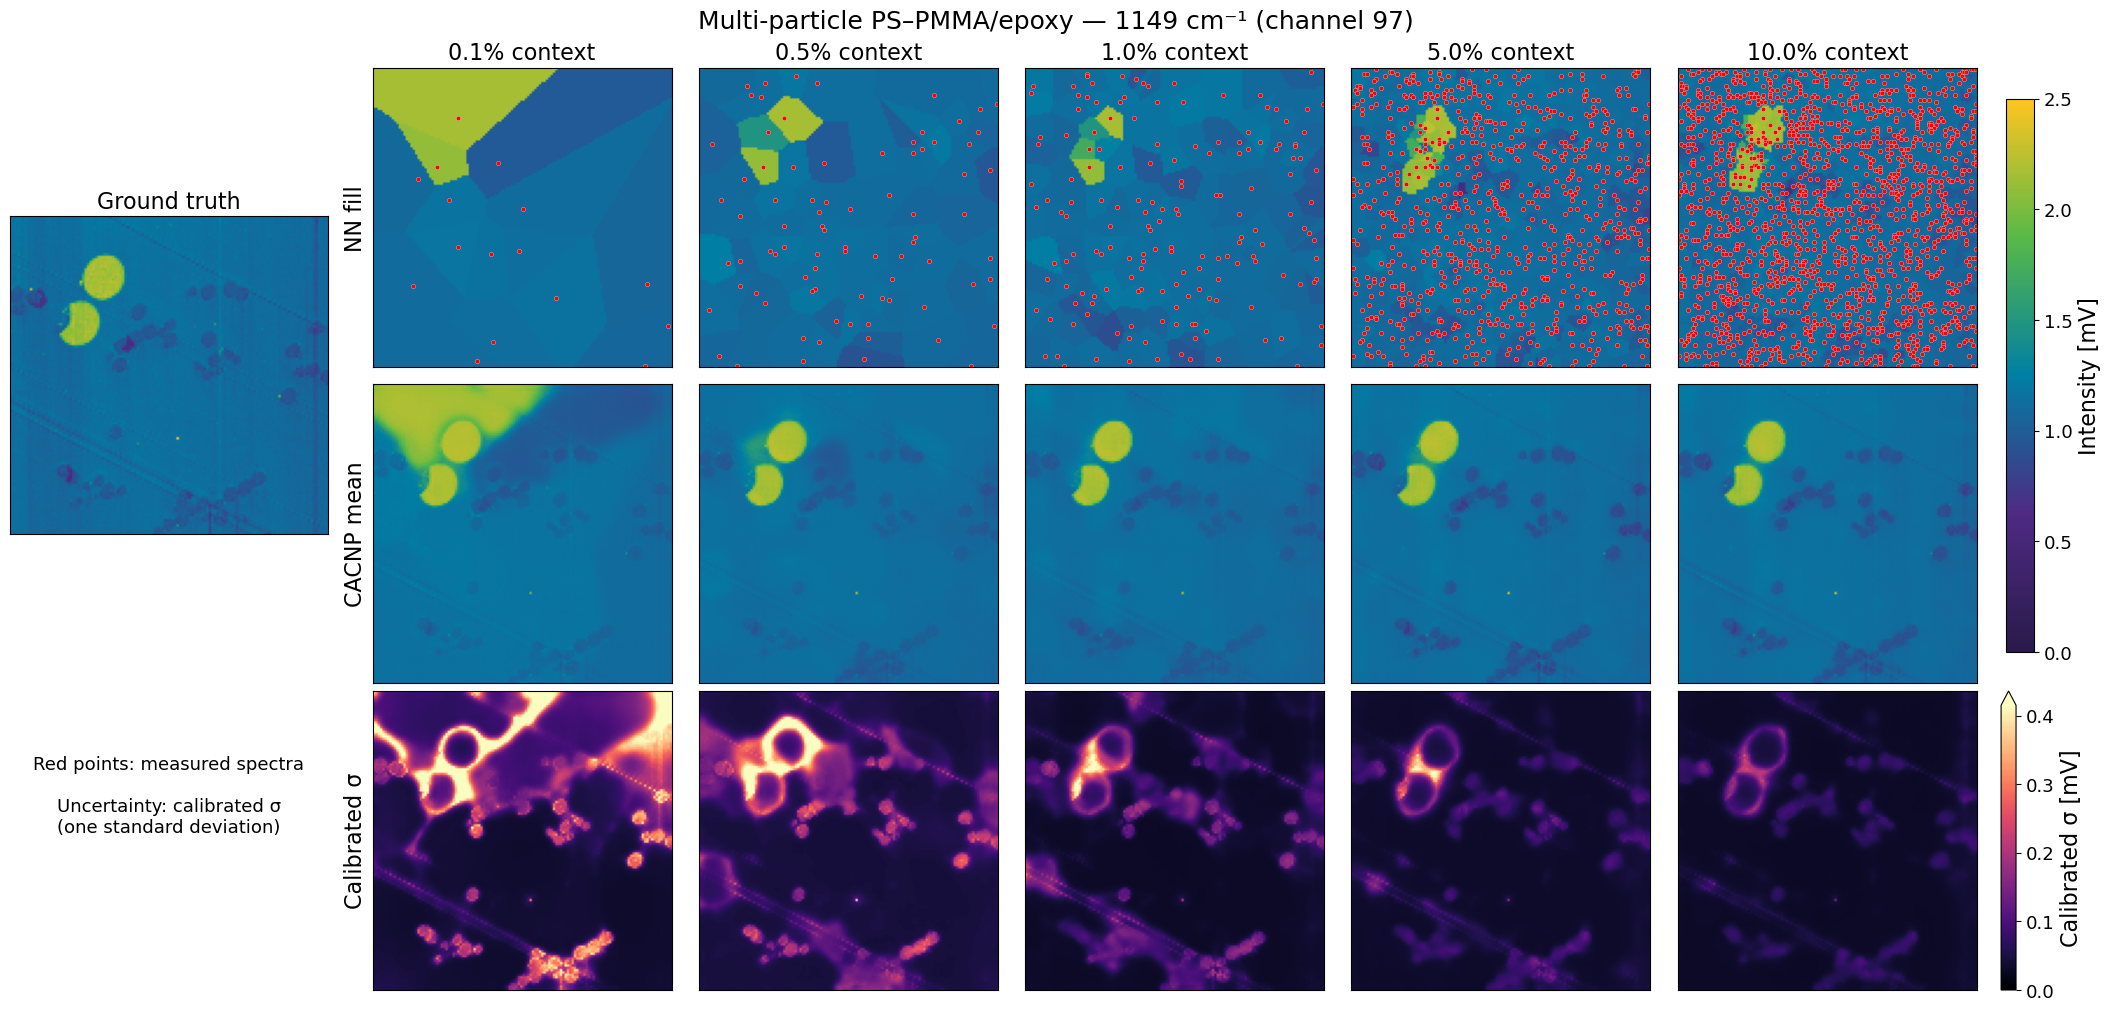

In [22]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from scipy.ndimage import distance_transform_edt

CUSTOM_CMAP_HEX = ["#2A1A4A", "#4E2A84", "#007FA4", "#58B947", "#FFC520"]
cust_viridis = LinearSegmentedColormap.from_list("cust_cmap", CUSTOM_CMAP_HEX, N=256)
intensity_norm = Normalize(*INTENSITY_LIMITS)
sigma_slices = np.stack([sigmas_calibrated[f][:, :, SLICE_INDEX] for f in CONTEXT_FRACTIONS])
sigma_limits = SIGMA_LIMITS
if sigma_limits is None:
    sigma_limits = (0.0, max(float(np.percentile(sigma_slices, 99)), 1e-8))
sigma_norm = Normalize(*sigma_limits)

fig = plt.figure(figsize=(21, 10), layout="constrained")
gs = fig.add_gridspec(3, len(CONTEXT_FRACTIONS) + 1)
ax_gt = fig.add_subplot(gs[0:2, 0])
ax_gt.imshow(cube_raw[:, :, SLICE_INDEX], cmap=cust_viridis, norm=intensity_norm)
ax_gt.set_title("Ground truth", fontsize=16)
ax_gt.set_xticks([])
ax_gt.set_yticks([])
ax_key = fig.add_subplot(gs[2, 0])
ax_key.axis("off")
ax_key.text(0.5, 0.65, "Red points: measured spectra\n\nUncertainty: calibrated σ\n(one standard deviation)",
            ha="center", va="center", transform=ax_key.transAxes, fontsize=13)
intensity_axes, uncertainty_axes = [ax_gt], []

for i, fraction in enumerate(CONTEXT_FRACTIONS):
    mask = context_masks[fraction]
    nearest = distance_transform_edt(~mask, return_distances=False, return_indices=True)
    nn_slice = cube_raw[nearest[0], nearest[1], SLICE_INDEX]
    arrays = [nn_slice, reconstructions[fraction][:, :, SLICE_INDEX], sigma_slices[i]]
    labels = ["NN fill", "CACNP mean", "Calibrated σ"]
    for row, (values, label) in enumerate(zip(arrays, labels)):
        ax = fig.add_subplot(gs[row, i + 1])
        ax.imshow(values, cmap="magma" if row == 2 else cust_viridis,
                  norm=sigma_norm if row == 2 else intensity_norm)
        ax.set_xticks([])
        ax.set_yticks([])
        if i == 0:
            ax.set_ylabel(label, fontsize=16)
        if row == 0:
            ax.set_title(f"{fraction:.1%} context", fontsize=16)
            rows, cols = np.where(mask)
            ax.scatter(cols, rows, s=10, c="red", edgecolors="white", linewidths=0.2)
        (uncertainty_axes if row == 2 else intensity_axes).append(ax)

cbar_mu = fig.colorbar(ScalarMappable(norm=intensity_norm, cmap=cust_viridis),
                       ax=intensity_axes, location="right", pad=0.015, shrink=0.9)
cbar_mu.set_label("Intensity [mV]", fontsize=16)
cbar_sigma = fig.colorbar(ScalarMappable(norm=sigma_norm, cmap="magma"),
                          ax=uncertainty_axes, location="right", pad=0.015,
                          extend="max" if sigma_slices.max() > sigma_limits[1] else "neither")
cbar_sigma.set_label("Calibrated σ [mV]", fontsize=16)
for cbar in [cbar_mu, cbar_sigma]:
    cbar.ax.tick_params(labelsize=13)
fig.suptitle(f"Multi-particle PS–PMMA/epoxy — {wavenumbers[SLICE_INDEX]:.0f} cm⁻¹ (channel {SLICE_INDEX})",
             fontsize=18)
if SAVE_FIGURE:
    fig.savefig(FIGURE_PATH, dpi=300, bbox_inches="tight")
    print(f"Saved figure to {FIGURE_PATH}")
plt.show()


## Spectral comparisons with calibrated uncertainty

Each row shows one context fraction: the reconstructed image on the left and four spectra on the right, using the multi-particle locations from the paper plotting script. Gray dashed lines show measured ground truth; green lines show the CACNP mean. Shading and dashed bounds show **mean ± 2 calibrated standard deviations**. Each spectrum has a residual strip above it showing **prediction − ground truth**, with ±2σ around zero.

The figure reuses the predictions, calibrated uncertainties, and context masks above; it performs no new inference or sampling. Panel titles identify whether each location is **observed** or **unobserved** at that context fraction. An observed location is part of the final model context; its reconstruction is not an independent held-out evaluation. Supplied structure-image channels remain observed everywhere.

Change `SPECTRAL_LOCATIONS` (row, column), labels, axes limits, or save options at the top of the cell. The wavenumber array already matches the cube channel order; only the displayed axis direction is reversed. The ±2σ bands are empirical uncertainty estimates, not guaranteed coverage intervals.


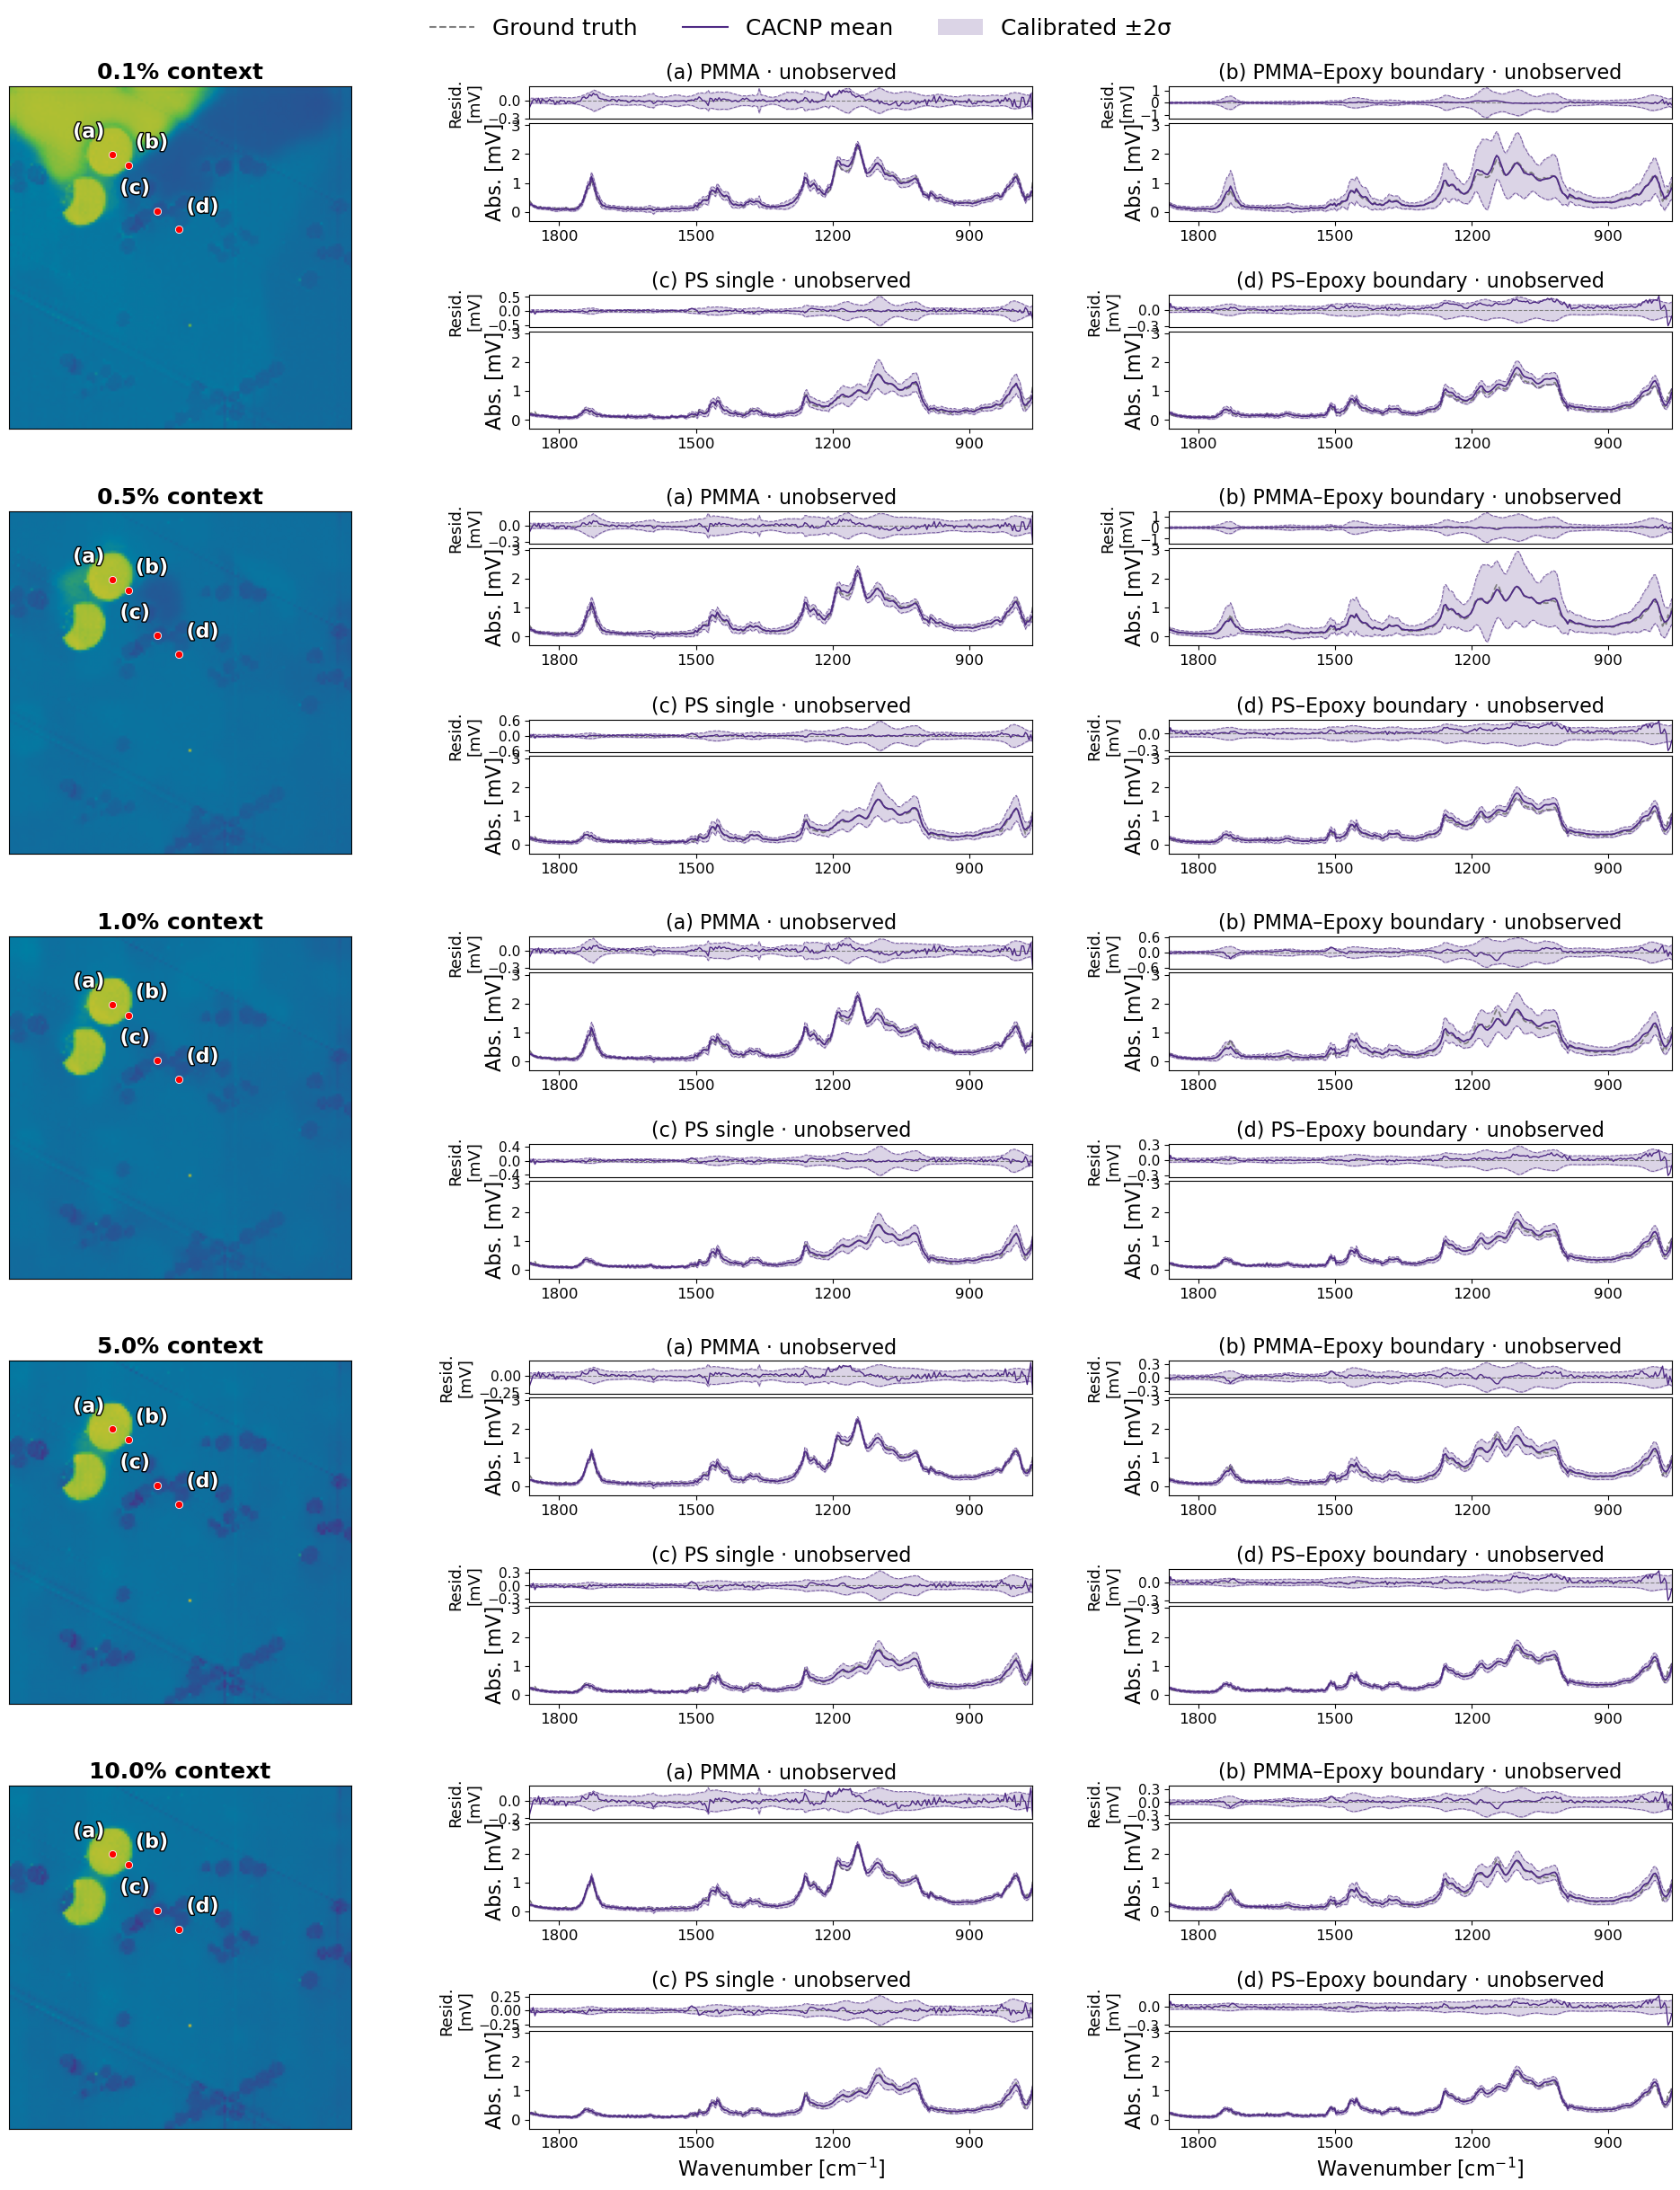

In [24]:
# Adjustable settings for plots. 
SPECTRAL_LOCATIONS = [(25, 38), (29, 44), (46, 55), (53, 63)]
SPECTRAL_POINT_LABELS = ["(a) PMMA", "(b) PMMA–Epoxy boundary",
                         "(c) PS single", "(d) PS–Epoxy boundary"]
SPECTRAL_COLOR = "#4E2A84"
SPECTRAL_YLIM = None  # None: one shared range including GT and all ±2σ bands.
RESIDUAL_YLIM = None  # None: each residual panel scales independently.
SAVE_SPECTRAL_FIGURE = False
SPECTRAL_FIGURE_PATH = OUTPUT_DIR / "multi_particle_spectral_comparison.png"

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
import matplotlib.patheffects as pe

x = np.asarray(wavenumbers).ravel()
if len(SPECTRAL_LOCATIONS) != 4 or len(SPECTRAL_POINT_LABELS) != 4:
    raise ValueError("Specify four locations and four panel labels")
if len(x) != cube_raw.shape[-1] or not np.isfinite(x).all():
    raise ValueError("Wavenumbers must match the cube channels")
if not (np.all(np.diff(x) > 0) or np.all(np.diff(x) < 0)):
    raise ValueError("Wavenumbers must be strictly monotonic")
for pos in SPECTRAL_LOCATIONS:
    if len(pos) != 2 or any(not isinstance(v, (int, np.integer)) for v in pos):
        raise ValueError("Locations must be integer (row, column) pairs")
    if not (0 <= pos[0] < height and 0 <= pos[1] < width):
        raise ValueError(f"Location {pos} is outside the image")

spectral_bounds = []
for fraction in CONTEXT_FRACTIONS:
    mu_cube = reconstructions[fraction]
    sigma_cube = sigmas_calibrated[fraction]  # Already in mV and calibrated: do not rescale.
    if mu_cube.shape != cube_raw.shape or sigma_cube.shape != cube_raw.shape:
        raise ValueError("Prediction and sigma cubes must match ground truth")
    for row, col in SPECTRAL_LOCATIONS:
        truth = cube_raw[row, col]
        mu = mu_cube[row, col]
        sigma = sigma_cube[row, col]
        if not all(np.isfinite(v).all() for v in (truth, mu, sigma)) or np.any(sigma < 0):
            raise ValueError("Selected spectra must be finite and sigmas nonnegative")
        spectral_bounds.extend([truth.min(), truth.max(), (mu - 2*sigma).min(), (mu + 2*sigma).max()])
if SPECTRAL_YLIM is None:
    lo, hi = float(np.min(spectral_bounds)), float(np.max(spectral_bounds))
    margin = 0.04 * max(hi - lo, 1e-6)
    shared_spectral_ylim = (lo - margin, hi + margin)
else:
    shared_spectral_ylim = SPECTRAL_YLIM

spectral_fig = plt.figure(figsize=(20, 4.8 * len(CONTEXT_FRACTIONS) + 0.7))
outer = spectral_fig.add_gridspec(
    len(CONTEXT_FRACTIONS), 2, width_ratios=[1, 2.65],
    left=0.035, right=0.985, bottom=0.035, top=0.955, hspace=0.24, wspace=0.17,
)
for j, fraction in enumerate(CONTEXT_FRACTIONS):
    ax_image = spectral_fig.add_subplot(outer[j, 0])
    ax_image.imshow(reconstructions[fraction][:, :, SLICE_INDEX],
                    cmap=cust_viridis, vmin=INTENSITY_LIMITS[0], vmax=INTENSITY_LIMITS[1])
    ax_image.set_title(f"{fraction:.1%} context", fontsize=18, fontweight="bold")
    ax_image.set_xticks([])
    ax_image.set_yticks([])
    for p, (row, col) in enumerate(SPECTRAL_LOCATIONS):
        ax_image.scatter(col, row, s=35, c="red", edgecolors="white", linewidths=0.6)
        left = p in (0, 2)
        txt = ax_image.annotate(
            f"({chr(97+p)})", (col, row), xytext=(-6 if left else 6, 10),
            textcoords="offset points", ha="right" if left else "left", va="bottom",
            color="white", fontsize=16, fontweight="bold",
        )
        txt.set_path_effects([pe.withStroke(linewidth=2, foreground="black")])
    panels = outer[j, 1].subgridspec(2, 2, hspace=0.55, wspace=0.27)
    for p, (row, col) in enumerate(SPECTRAL_LOCATIONS):
        pair = panels[p//2, p%2].subgridspec(2, 1, height_ratios=[1, 3], hspace=0.06)
        ax_res = spectral_fig.add_subplot(pair[0])
        ax_spec = spectral_fig.add_subplot(pair[1], sharex=ax_res)
        truth = cube_raw[row, col]
        mu = reconstructions[fraction][row, col]
        two_sigma = 2 * sigmas_calibrated[fraction][row, col]
        ax_spec.plot(x, truth, color="gray", linestyle="--", lw=1.3)
        ax_spec.plot(x, mu, color=SPECTRAL_COLOR, lw=1.3)
        ax_spec.fill_between(x, mu-two_sigma, mu+two_sigma, color=SPECTRAL_COLOR, alpha=0.20)
        ax_res.axhline(0, color="gray", linestyle="--", lw=0.8)
        ax_res.plot(x, mu-truth, color=SPECTRAL_COLOR, lw=1.0)
        ax_res.fill_between(x, -two_sigma, two_sigma, color=SPECTRAL_COLOR, alpha=0.20)
        for bound in (mu-two_sigma, mu+two_sigma):
            ax_spec.plot(x, bound, color=SPECTRAL_COLOR, ls="--", lw=0.7, alpha=0.7)
        for bound in (-two_sigma, two_sigma):
            ax_res.plot(x, bound, color=SPECTRAL_COLOR, ls="--", lw=0.7, alpha=0.7)
        status = "observed" if context_masks[fraction][row, col] else "unobserved"
        ax_res.set_title(f"{SPECTRAL_POINT_LABELS[p]} · {status}", fontsize=16)
        ax_res.set_ylabel("Resid.\n[mV]", fontsize=13)
        ax_spec.set_ylabel("Abs. [mV]", fontsize=16)
        ax_spec.set_ylim(*shared_spectral_ylim)
        if RESIDUAL_YLIM is not None:
            ax_res.set_ylim(*RESIDUAL_YLIM)
        ax_res.yaxis.set_major_locator(MaxNLocator(nbins=2))
        ax_spec.yaxis.set_major_locator(MaxNLocator(nbins=4))
        ax_spec.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax_spec.set_xlim(float(x.max()), float(x.min()))
        ax_res.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
        ax_res.tick_params(axis="y", labelsize=11)
        ax_spec.tick_params(labelsize=12)
        if p >= 2 and j == len(CONTEXT_FRACTIONS)-1:
            ax_spec.set_xlabel(r"Wavenumber [cm$^{-1}$]", fontsize=16)

spectral_fig.legend(handles=[
    Line2D([], [], color="gray", ls="--", label="Ground truth"),
    Line2D([], [], color=SPECTRAL_COLOR, label="CACNP mean"),
    Patch(facecolor=SPECTRAL_COLOR, alpha=0.20, label="Calibrated ±2σ"),
], loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=3, frameon=False, fontsize=18)
if SAVE_SPECTRAL_FIGURE:
    spectral_fig.savefig(SPECTRAL_FIGURE_PATH, dpi=300, bbox_inches="tight")
    print(f"Saved figure to {SPECTRAL_FIGURE_PATH}")
plt.show()
